# Graficación en en Python

En este notebook se utilizaron NumPy y Matplotlib para analizar datos y generar gráficas en Python. Se trabajó con datos de manchas solares, incluyendo el cálculo de una media móvil para suavizar las variaciones. También se estudió el mapeo logístico mediante el diagrama de Feigenbaum para observar la transición hacia el caos. Finalmente, se generó el conjunto de Mandelbrot mediante iteraciones en el plano complejo

In [1]:
# Primero vamos a importar las librerias que vamos a usar
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 1. Gráfica de datos experimentales

### (a) Escribe un programa que lea los datos y haga una grafica de las manchas solares en funcion del tiempo.

In [2]:
entrada = open("data/manchasolares.txt", "r")    # esto es un buffer
datos = [[], []]
for linea in entrada:
    #print(linea)
    palabras = linea.split()
    palabras = list(map(float, palabras))
    for j in range(len(palabras)):
        datos[j].append(palabras[j])

    #print(palabras)
datos = np.array(datos)

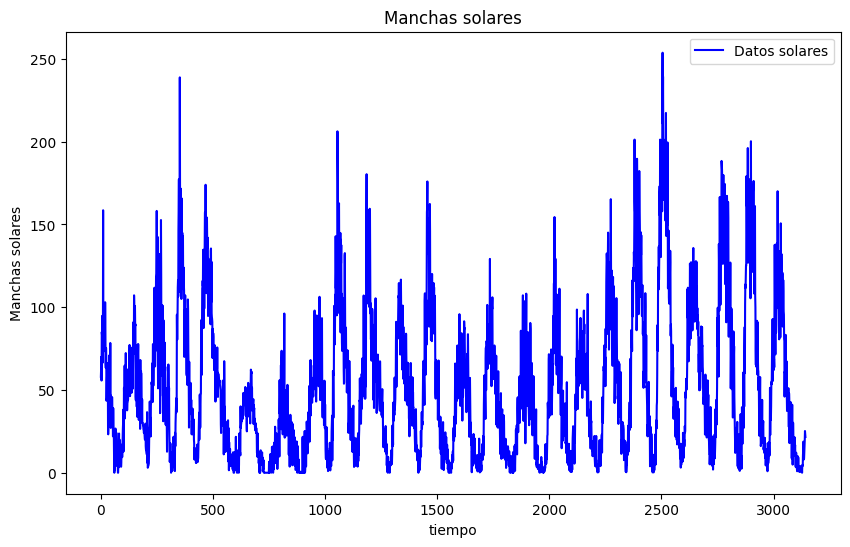

In [3]:
plt.figure(figsize=(10,6))
plt.plot(datos[0], datos[1], label = "Datos solares", color = "blue")
plt.title("Manchas solares")
plt.ylabel("Manchas solares")
plt.xlabel("tiempo")
plt.legend(loc = "best")

### (b) Modifica tu programa para mostrar solo los primeros 1000 datos (experimentales) en la grafica.  ́

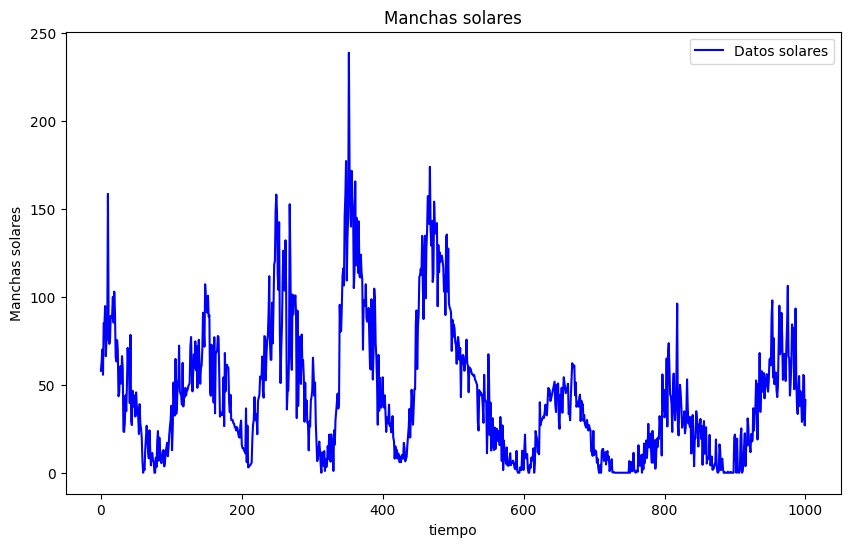

In [4]:
N = 1000
plt.figure(figsize=(10,6))
plt.plot(datos[0, :N+1], datos[1, :N+1], label = "Datos solares", color = "blue")
plt.title("Manchas solares")
plt.ylabel("Manchas solares")
plt.xlabel("tiempo")
plt.legend(loc = "best")

### Modifica nuevamente tu programa para calcular y graficar la media (promedio) móvil de los datos

In [5]:
# Vamos a usar un psudocódigo
"""tenemos un arreglo de N números 
 para i en los números:
    vamos a crear arreglos de -5,5
    para cada uno de esos arreglos:
        Hacemos la media móvil
    """

'tenemos un arreglo de N números \n para i en los números:\n    vamos a crear arreglos de -5,5\n    para cada uno de esos arreglos:\n        Hacemos la media móvil\n    '

In [6]:
# Vamos a definir variables
r = 5
Y_k=0
# vamos a utilizar una lista
valores_media = []
for j in range(10, len(datos[1]+1)): # Vamos a  necesitar que nuestros listas sean de 11 datos, que incie en 11 es porque va a ser el primero en la lista indexados por j
    # generamos nuestros arreglos de 11 datos que van de -5 hasta 5 
    valores= datos[1,j -2*r:j+1]
    tiempo = datos[0,j -2*r:j+1]
    #print(len(valores))
    Y_k =(1/(2*r+1)) * np.sum(valores)
    valores_media.append(Y_k)


In [7]:
len(valores_media)

3133

In [8]:
tiempo_media = np.arange(r, r + len(valores_media))

In [9]:
len(tiempo_media)

3133

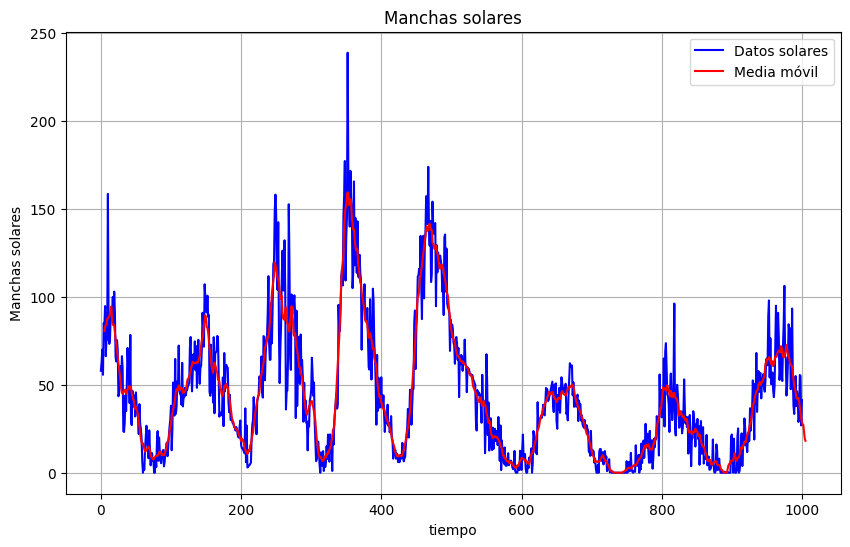

In [10]:
N = 1000
plt.figure(figsize=(10,6))
plt.plot(datos[0, :N+1], datos[1, :N+1], label = "Datos solares", color = "blue")
plt.plot(tiempo_media[:N+1],valores_media[:N+1], label = "Media móvil", color = "red")
plt.title("Manchas solares")
plt.ylabel("Manchas solares")
plt.xlabel("tiempo")
plt.legend(loc = "best")
plt.grid()

## La gráfica de Feigenbaum

### Programa que muestre el comportamiento del mapeo logístico

In [57]:
#Creamos los valores de r
r_valores = np.arange(1, 4.01, 0.01)


In [58]:
#vamos a programar la ecuación 
r_plot = []
x_plot = []

for r in r_valores:
    x = 0.5
    for _ in range(1000):
        x = r*x*(1-x)
    for _ in range(1000):
        x = r*x*(1-x)
        r_plot.append(r)
        x_plot.append(x)


C:\Users\Piloto 01\AppData\Local\Temp\ipykernel_17580\510925297.py:8: RuntimeWarning: overflow encountered in scalar multiply
  x = r*x*(1-x)


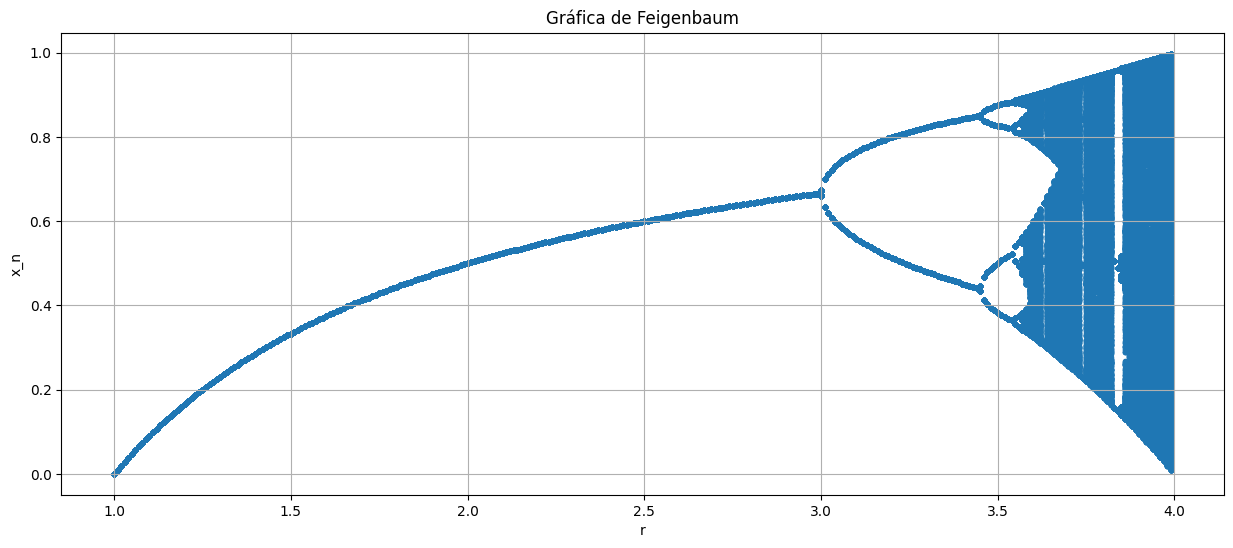

In [66]:
plt.figure(figsize=(15,6))
plt.scatter(r_plot, x_plot, marker=".")
plt.xlabel('r')
plt.ylabel('x_n')
plt.title('Gráfica de Feigenbaum')
plt.grid()
plt.show()

### (b) “el borde del caos”

Podemos notar que los valores de r = 3,3.45 y 3.55 comienzan las difuraciones, pero donde empieza el caos es en 3.55

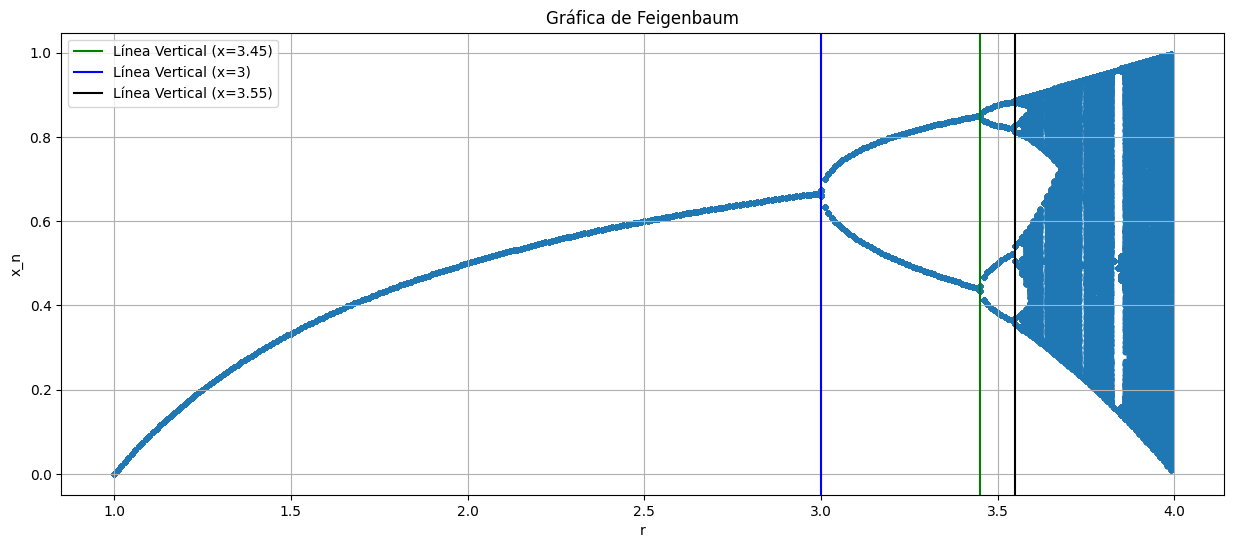

In [71]:
plt.figure(figsize=(15,6))
plt.scatter(r_plot, x_plot, marker=".")
plt.xlabel('r')
plt.ylabel('x_n')
plt.title('Gráfica de Feigenbaum')
plt.axvline(x=3.45, color='green', linestyle='-', label='Línea Vertical (x=3.45)')
plt.axvline(x=3, color='blue', linestyle='-', label='Línea Vertical (x=3)')
plt.axvline(x=3.55, color='black', linestyle='-', label='Línea Vertical (x=3.55)')
plt.grid()
plt.legend()
plt.show()

### (c) optimización (utilicé IA)

C:\Users\Piloto 01\AppData\Local\Temp\ipykernel_17580\3239180991.py:9: RuntimeWarning: overflow encountered in multiply
  x = r*x*(1-x)


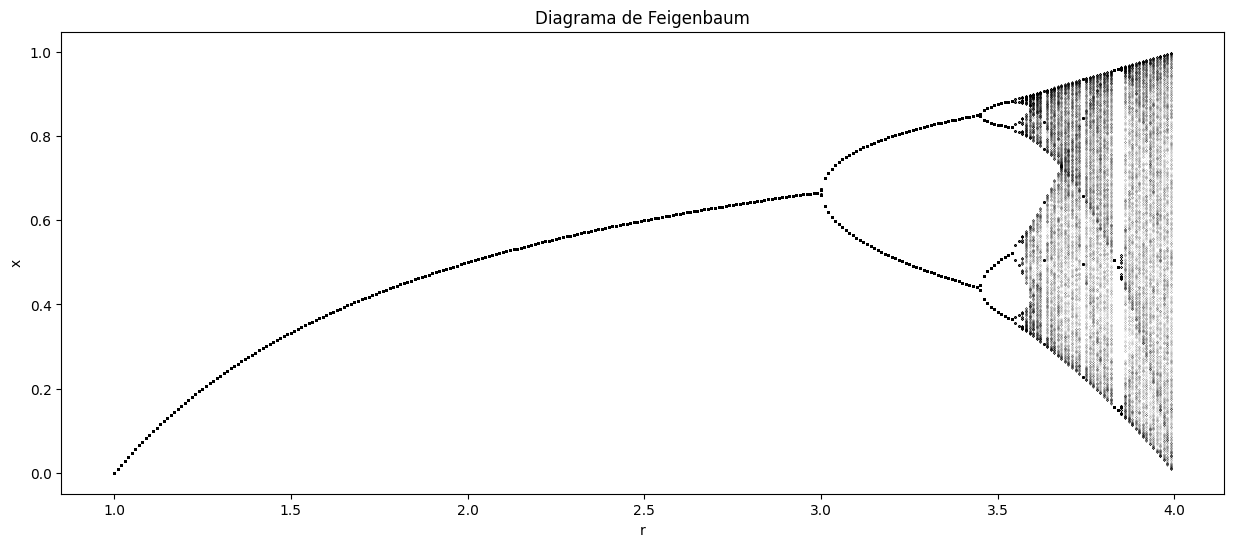

In [79]:
# Valores de r
r = np.arange(1.0, 4.01, 0.01)

# Condición inicial x0 = 0.5 para cada valor de r
x = np.full(len(r), 0.5)

# 1000 iteraciones para eliminar el transitorio
for i in range(1000):
    x = r*x*(1-x)

# Guardamos las siguientes 1000 iteraciones
X = []

for i in range(1000):
    x = r*x*(1-x)
    X.append(x.copy())

X = np.array(X)

plt.figure(figsize= (15,6))
# Graficamos
for i in range(1000):
    plt.plot(r, X[i], 'k.', ms = 0.1 )

plt.xlabel("r")
plt.ylabel("x")
plt.title("Diagrama de Feigenbaum")
plt.show()

### Crear una imagen del conjunto de Mandelbrot

In [81]:

# Definimos varias cosas como
N = 1000 # Tamaño de la cuadrícula
iteraciones = 100 # Número máximo de iteraciones

# Valores de x e y entre -2 y 2
x = np.linspace(-2, 2, N)
y = np.linspace(-2, 2, N)

# necesiatamos una matriz donde guardaremos si cada punto pertenece al conjunto
mandelbrot = np.zeros((N, N))

In [82]:
# Recorremos todos los puntos de la cuadrícula
for i in range(N):
    for j in range(N):
        c = x[j] + 1j*y[i]

        # Condición inicial
        z = 0

        pertenece = True

        # Iteramos z_(n+1) = z_n^2 + c
        for n in range(iteraciones):

            z = z**2 + c

            # Si |z| > 2, el punto no pertenece al conjunto
            if abs(z) > 2:
                pertenece = False
                break

        # 1 = pertenece al conjunto
        # 0 = no pertenece
        if pertenece:
            mandelbrot[i, j] = 1

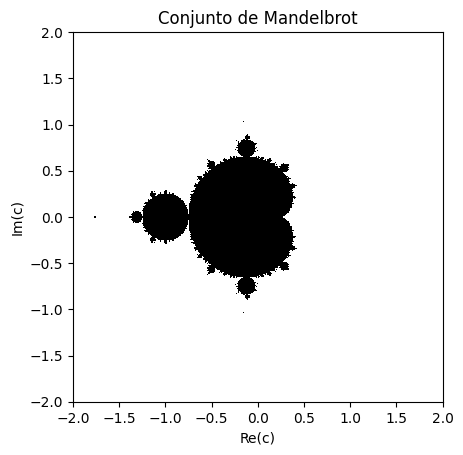

In [ ]:
plt.imshow(mandelbrot, extent=[-2, 2, -2, 2], origin="lower", cmap="binary", interpolation="nearest")
plt.xlabel("Re(c)")
plt.ylabel("Im(c)")
plt.title("Conjunto de Mandelbrot")
plt.show()

# Códigos de Ayuda
códigos en los que me apoyé

## Ejercicio 2

In [29]:
frutas = ["manzana", "banana", "cereza"]

for i, fruta in enumerate(frutas):
    print(f"Posición {i}: {fruta}")

Posición 0: manzana
Posición 1: banana
Posición 2: cereza


In [37]:
lista = [1,2,3,4,5,82,46]
max(lista)

82

In [24]:
r = 3
X_n = 1/2
for i in range(0,2*N+1):
        print(X_n)
        X_n = r*X_n*(1-X_n)
        

0.5
0.75
0.5625
0.73828125
0.5796661376953125
0.7309599195141345
0.5899725467340735
0.7257148225025549
0.5971584567079203
0.7216807028704055
0.6025729979246489
0.7184363402902498
0.6068566957218066
0.7157449397382518
0.6103623629320143
0.713460446544187
0.6133039132834688
0.7114866697039566
0.6158201656125887
0.7097570677124175
0.6180059176340649
0.7082238102100269
0.6199285345848561
0.706851439776987
0.6216374455865626
0.7056129954935281
0.6231698882525353
0.7044875358835738
0.6245545430047923
0.7034584974506021
0.6258139194454301
0.7025125730213365
0.6269659733048335
0.701638924868269
0.6280252319339057
0.7008286199648089
0.6290035962090911
0.7000742164953654
0.629910923681297
0.6993694557248167
0.630755460371971
0.6987090287487417
0.6315441656811952
0.6980883974257147
0.6322829604159362
0.6975036551507876
0.6329769186062363
0.6969514173539713
0.6336304176067855
0.6964287344707083
0.6342472568227079
0.6959330221067338
0.6348307525443665
0.6954620045049594
0.6353838143847096
0.6950136

# Ejercicio 1

In [11]:
# Vamos a definir variables
r = 5
# vamos a utilizar una lista
media_movil = []
tiempo_media = []
for j in range(10, len(datos[1]+1)):
    
    valores= datos[1,j -2*r+1 :j+1]
    tiempo = datos[0,j -2*r:j+1]
    tiempo_media.append(tiempo)

In [12]:
tiempo_media

[array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.]),
 array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.]),
 array([ 2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.]),
 array([ 3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.]),
 array([ 4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14.]),
 array([ 5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14., 15.]),
 array([ 6.,  7.,  8.,  9., 10., 11., 12., 13., 14., 15., 16.]),
 array([ 7.,  8.,  9., 10., 11., 12., 13., 14., 15., 16., 17.]),
 array([ 8.,  9., 10., 11., 12., 13., 14., 15., 16., 17., 18.]),
 array([ 9., 10., 11., 12., 13., 14., 15., 16., 17., 18., 19.]),
 array([10., 11., 12., 13., 14., 15., 16., 17., 18., 19., 20.]),
 array([11., 12., 13., 14., 15., 16., 17., 18., 19., 20., 21.]),
 array([12., 13., 14., 15., 16., 17., 18., 19., 20., 21., 22.]),
 array([13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23.]),
 array([14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24.]),
 array([15., 16., 17., 18

In [13]:
datos[0, :4]

array([0., 1., 2., 3.])

In [14]:
for i in range(0,(r*20)+1, 2*r+1 ):
    print(i)

0
11
22
33
44
55
66
77
88
99
